### 🔴 Section 1: Implement for MA's

#### ⚪ 1. Libraries

In [1]:
### Cell 1 
import pandas as pd
import scipy.io
import numpy as np
import time
from scipy.io import loadmat
from sklearn.preprocessing import MinMaxScaler
from scipy.spatial.distance import cdist
from sklearn.metrics import roc_auc_score, average_precision_score

#### ⚪ 2. Extract indices from .csv file

In [2]:
### Cell 2
# --- Configuration ---
csv_file_path = '/media/mine/Mine/3.Main-Ubuntu-Envs/2.Thesis-Env/3.Datasets/mammographyori.csv'

def get_ma_indices(df, feature_name, low, high):
    condition = (df[feature_name] >= low) & (df[feature_name] <= high)
    subset = df[condition]
    indices = subset.index.to_numpy()
    counts = subset['label'].value_counts()
    return indices, counts

df_original = pd.read_csv(csv_file_path, header=None)
df_original.columns = ['c1', 'c2', 'c3', 'c4', 'c5', 'c6', 'label']
print(f"Shape of the original dataset: {df_original.shape} (rows, columns)")

ma_conditions = {
    'MA1': ('c4', -0.9, 2),
    'MA2': ('c5', -0.4, 1),
    'MA3': ('c6', -1, 1),
}

ma_indices = {}
ma_label_counts = {}
for name, (feature, low, high) in ma_conditions.items():
    indices, counts = get_ma_indices(df_original, feature, low, high)
    ma_indices[name] = indices
    ma_label_counts[name] = counts
    print(f"{name} Condition: Feature '{feature}' in [{low}, {high}]")
    print(f"  samples = {len(indices)}")
    print(f"  label counts =\n{counts}\n")

Shape of the original dataset: (11183, 7) (rows, columns)
MA1 Condition: Feature 'c4' in [-0.9, 2]
  samples = 10951
  label counts =
label
1    10747
2      204
Name: count, dtype: int64

MA2 Condition: Feature 'c5' in [-0.4, 1]
  samples = 10098
  label counts =
label
1    10022
2       76
Name: count, dtype: int64

MA3 Condition: Feature 'c6' in [-1, 1]
  samples = 8263
  label counts =
label
1    8209
2      54
Name: count, dtype: int64



#### ⚪ 3. Create X_tem lists for MA1/MA2/MA3

In [3]:
### Cell 3
X_tem_ma1 = ma_indices['MA1'].tolist()
X_tem_ma2 = ma_indices['MA2'].tolist()
X_tem_ma3 = ma_indices['MA3'].tolist()

print('MA1 size:', len(X_tem_ma1))
print('MA2 size:', len(X_tem_ma2))
print('MA3 size:', len(X_tem_ma3))

MA1 size: 10951
MA2 size: 10098
MA3 size: 8263


In [4]:
### Cell 4
# ==========================================
# 1. Baseline Implementation (Original)
# ==========================================
def WNCROD_original(data, X_tem, lammda):
    n, m = data.shape
    X = np.zeros(n)
    X[X_tem] = 1
    D1 = m / 3
    D2 = m / 2
    D3 = 0.9 * m
    delta = np.zeros(m)
    ID = np.all(data <= 1, axis=0)
    delta[ID] = np.std(data[:, ID], axis=0) / lammda
    Lower = np.zeros((m, n))

    for col in range(m):
        RM_tem = cdist(data[:, [col]], data[:, [col]], metric='cityblock') <= delta[col]
        Lower_temp = np.min(np.maximum(1 - RM_tem, np.tile(X, (n, 1))), axis=1)
        Lower[col, :Lower_temp.shape[0]] = Lower_temp

    IB = np.tile(X, (m, 1)) - Lower
    NEB = np.min(IB, axis=0)
    NPB = IB - np.tile(NEB, (m, 1))
    n_X = int(sum(X))
    weight = np.zeros((n_X, m))

    for col in range(m):
        RM_tem = cdist(data[:, [col]], data[:, [col]], metric='cityblock') <= delta[col]
        weight_x = []
        for i in range(n_X):
            temp1 = RM_tem[X_tem[i], :]
            weight_temp = 1 - (np.sqrt((np.sum(np.minimum(temp1, X))) / n_X))
            weight_x.append(weight_temp)
        weight[:len(weight_x), col] = weight_x
    D_tem = np.zeros((n, n))

    for col in range(m):
        RM_tem = cdist(data[:, [col]], data[:, [col]], metric='cityblock') <= delta[col]
        D_tem += RM_tem

    NOM = m - D_tem
    X_OM = NOM[np.ix_(X_tem, X_tem)]
    NEB_num = np.zeros((n_X, m))
    Lower_num = np.zeros((n_X, m))
    NPB_num = np.zeros((n_X, m))

    for col in range(m):
        temp2 = Lower[col, :]
        temp3 = NPB[col, :]
        for i in range(n_X):
            temp1 = X_OM[i, :]
            NEB_num[i, col] = np.sum(np.minimum(NEB[X_tem], temp1 <= D1))
            NPB_num[i, col] = np.sum(np.minimum(temp3[X_tem], temp1 >= D2))
            Lower_num[i, col] = np.sum(np.minimum(temp2[X_tem], temp1 >= D3))
    MNOF = np.mean(((NEB_num + Lower_num + NPB_num) / n_X) * weight, axis=1)
    return MNOF


# ==========================================
# 2. Optimized Implementation (Claude)
# ==========================================
def _neighbour_interval(x, s, rank, eps):
    k = x.size
    if not eps >= 0:
        z = np.zeros(k, dtype=np.intp)
        return z, z.copy()

    lo = np.zeros(k, dtype=np.intp)
    hi = rank.astype(np.intp, copy=True)
    while True:
        act = lo < hi
        if not act.any():
            break
        mid = (lo + hi) >> 1
        ok = np.abs(x - s[mid]) <= eps
        np.copyto(hi, mid, where=act & ok)
        np.copyto(lo, mid + 1, where=act & ~ok)
    left = lo

    lo = rank.astype(np.intp, copy=True)
    hi = np.full(k, k - 1, dtype=np.intp)
    while True:
        act = lo < hi
        if not act.any():
            break
        mid = (lo + hi + 1) >> 1
        ok = np.abs(x - s[mid]) <= eps
        np.copyto(lo, mid, where=act & ok)
        np.copyto(hi, mid - 1, where=act & ~ok)
    return left, lo + 1

def _has_outside_neighbour_sorted(x, out_vals, eps):
    res = np.zeros(x.size, dtype=bool)
    if out_vals.size == 0 or not eps >= 0:
        return res
    s = np.sort(out_vals)
    pos = np.searchsorted(s, x, side="left")
    up = np.minimum(pos, s.size - 1)
    dn = np.maximum(pos - 1, 0)
    np.logical_or((pos < s.size) & (np.abs(x - s[up]) <= eps),
                  (pos > 0) & (np.abs(x - s[dn]) <= eps), out=res)
    return res

def _has_outside_neighbour_dense(x, out_vals, eps, block):
    res = np.zeros(x.size, dtype=bool)
    if out_vals.size == 0:
        return res
    for start in range(0, x.size, block):
        stop = min(start + block, x.size)
        d = np.abs(x[start:stop, None] - out_vals[None, :])
        np.any(d <= eps, axis=1, out=res[start:stop])
    return res

def WNCROD_optimized(data, X_tem, lammda, block_size=None, sorted_kernel=True):
    data = np.asarray(data)
    if data.ndim != 2:
        raise ValueError("data must be a 2-D (samples x attributes) array")
    n, m = data.shape
    if m == 0:
        raise ValueError("data must have at least one attribute")

    X_tem = np.asarray(X_tem)
    if X_tem.dtype == np.bool_:
        X_idx = np.flatnonzero(X_tem)
    else:
        X_idx = np.ascontiguousarray(X_tem, dtype=np.intp).ravel()
    n_X = X_idx.size
    if n_X == 0:
        return np.zeros(0, dtype=np.float64)

    in_X = np.zeros(n, dtype=bool)
    in_X[X_idx] = True
    if int(np.count_nonzero(in_X)) != n_X:
        raise ValueError("X_tem must hold unique object indices")
    C_idx = np.flatnonzero(~in_X)

    D1, D2, D3 = m / 3, m / 2, 0.9 * m
    delta = np.zeros(m)
    ID = np.all(data <= 1, axis=0)
    if ID.any():
        delta[ID] = np.std(data[:, ID], axis=0) / lammda

    om = np.arange(m + 1)
    s1, s2, s3 = om <= D1, om >= D2, om >= D3
    k1 = m - int(om[s1].max()) if s1.any() else None
    k2 = m - int(om[s2].min()) if s2.any() else None
    k3 = m - int(om[s3].min()) if s3.any() else None

    work = np.ascontiguousarray(data, dtype=np.float64)
    if sorted_kernel and not np.isfinite(work).all():
        raise ValueError("sorted_kernel=True requires finite data; use sorted_kernel=False for NaN/inf input")
    VX = np.ascontiguousarray(work[X_idx].T)
    VC = np.ascontiguousarray(work[C_idx].T)
    del work

    if block_size is None:
        block_size = min(n_X, max(64, (1 << 21) // n_X))
    block_size = int(min(max(1, int(block_size)), n_X))

    POS = np.empty((m, n_X), dtype=bool)
    hit = np.empty((n_X, m), dtype=np.float64)
    if sorted_kernel:
        rank_all = np.empty((m, n_X), dtype=np.int32)
        lo_all = np.empty((m, n_X), dtype=np.int32)
        hi_all = np.empty((m, n_X), dtype=np.int32)
        iota = np.arange(n_X, dtype=np.intp)

    for j in range(m):
        v, eps = VX[j], delta[j]
        if sorted_kernel:
            order = np.argsort(v, kind="stable")
            s = v[order]
            rank = np.empty(n_X, dtype=np.intp)
            rank[order] = iota
            lo, hi = _neighbour_interval(v, s, rank, eps)
            rank_all[j] = rank
            lo_all[j] = lo
            hi_all[j] = hi
            hit[:, j] = hi - lo
            POS[j] = ~_has_outside_neighbour_sorted(v, VC[j], eps)
        else:
            POS[j] = ~_has_outside_neighbour_dense(v, VC[j], eps, block_size)

    NIB = ~POS
    NEB = NIB.all(axis=0)
    NPB = NIB & ~NEB
    del NIB

    gemm_dt = np.float32 if n_X < (1 << 24) else np.float64
    NPB_f = np.ascontiguousarray(NPB.T, dtype=gemm_dt)
    POS_f = np.ascontiguousarray(POS.T, dtype=gemm_dt)

    cnt_dt = np.uint8 if m <= 255 else (np.uint16 if m <= 65535 else np.uint32)
    cnt = np.empty((block_size, n_X), dtype=cnt_dt)
    buf1 = np.empty((block_size, n_X), dtype=bool)
    buf2 = np.empty((block_size, n_X), dtype=bool)
    fbuf = np.empty((block_size, n_X), dtype=gemm_dt)
    dbuf = None if sorted_kernel else np.empty((block_size, n_X), np.float64)

    neb_cnt = np.zeros(n_X, dtype=np.float64)
    npb_cnt = np.zeros((n_X, m), dtype=np.float64)
    pos_cnt = np.zeros((n_X, m), dtype=np.float64)

    for start in range(0, n_X, block_size):
        stop = min(start + block_size, n_X)
        b = stop - start
        c, a, t = cnt[:b], buf1[:b], buf2[:b]
        c.fill(0)

        for j in range(m):
            if sorted_kernel:
                r = rank_all[j]
                np.greater_equal(r, lo_all[j][start:stop, None], out=a)
                np.less(r, hi_all[j][start:stop, None], out=t)
                np.logical_and(a, t, out=a)
            else:
                v, d = VX[j], dbuf[:b]
                np.subtract(v[start:stop, None], v[None, :], out=d)
                np.abs(d, out=d)
                np.less_equal(d, delta[j], out=a)
                hit[start:stop, j] = np.count_nonzero(a, axis=1)
            c += a

        if k1 is not None:
            np.greater_equal(c, k1, out=a)
            np.logical_and(a, NEB, out=a)
            neb_cnt[start:stop] = np.count_nonzero(a, axis=1)
        if k2 is not None:
            np.less_equal(c, k2, out=a)
            np.copyto(fbuf[:b], a)
            npb_cnt[start:stop] = fbuf[:b] @ NPB_f
        if k3 is not None:
            np.less_equal(c, k3, out=a)
            np.copyto(fbuf[:b], a)
            pos_cnt[start:stop] = fbuf[:b] @ POS_f

    weight = 1 - np.sqrt(hit / n_X)
    ndf = neb_cnt[:, None] + pos_cnt + npb_cnt
    return np.mean((ndf / n_X) * weight, axis=1)

#### ⚪ 4. Run WNCROD for MA1, MA2, and MA3

In [5]:
### Cell 5
# 1) Load data and normalize once
mat = loadmat('/media/mine/Mine/3.Main-Ubuntu-Envs/2.Thesis-Env/3.Datasets/mammography.mat')
full_data = mat['trandata']            # shape = (n_samples, 7)
X = full_data[:, :6]
y = full_data[:, 6].astype(int)
scaler = MinMaxScaler()
X[:, 1:] = scaler.fit_transform(X[:, 1:])
print('Loaded and normalized data once for all MA subsets.')

# Validation & Timing Test on MA3 (smallest subset for quick validation)
print("\n--- Validation & Speedup Test (on MA3, λ = 0.5) ---")
t0 = time.perf_counter()
scores_orig = WNCROD_original(X, X_tem_ma3, lammda=0.5)
t_orig = time.perf_counter() - t0

t0 = time.perf_counter()
scores_opt = WNCROD_optimized(X, X_tem_ma3, lammda=0.5)
t_opt = time.perf_counter() - t0

# Check equivalence
max_diff = np.max(np.abs(scores_orig - scores_opt))
is_identical = np.allclose(scores_orig, scores_opt, atol=1e-12)

print(f"Original Time:  {t_orig:.4f} s")
print(f"Optimized Time: {t_opt:.4f} s")
print(f"Speedup Factor: {t_orig / t_opt:.2f}x")
print(f"Max absolute difference: {max_diff}")
print(f"Are outputs bitwise close (atol=1e-12)? {is_identical}")

# Standard evaluation helper function (now using the optimized code)
def evaluate_wncrod(data, labels, X_tem, lam=0.5):
    out_scores = WNCROD_optimized(data, X_tem, lammda=lam)
    return roc_auc_score(labels[X_tem], out_scores), average_precision_score(labels[X_tem], out_scores)

print('\nRunning WNCROD_optimized for MA1, MA2, MA3 with λ = 0.5')
for name, X_tem in [('MA1', X_tem_ma1), ('MA2', X_tem_ma2), ('MA3', X_tem_ma3)]:
    t0 = time.perf_counter()
    roc_auc, ap = evaluate_wncrod(X, y, X_tem, lam=0.5)
    elapsed = time.perf_counter() - t0
    print(f"{name} ({len(X_tem)} samples): ROC-AUC = {roc_auc:.4f}, AP = {ap:.4f} [Time: {elapsed:.2f} s]")

Loaded and normalized data once for all MA subsets.

--- Validation & Speedup Test (on MA3, λ = 0.5) ---
Original Time:  87.0226 s
Optimized Time: 1.2878 s
Speedup Factor: 67.57x
Max absolute difference: 0.0
Are outputs bitwise close (atol=1e-12)? True

Running WNCROD_optimized for MA1, MA2, MA3 with λ = 0.5
MA1 (10951 samples): ROC-AUC = 0.8931, AP = 0.3550 [Time: 2.07 s]
MA2 (10098 samples): ROC-AUC = 0.7745, AP = 0.0626 [Time: 2.30 s]
MA3 (8263 samples): ROC-AUC = 0.7748, AP = 0.0827 [Time: 1.20 s]


#### ⚪ 5. Run WNCROD only on MA1 for λ = 0.1 to 2.0

In [6]:
### Cell 6
# Run WNCROD_optimized only on MA1 for λ = 0.1 to 2.0
lambda_list_ma1 = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0,
                   1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2.0,]
ma1_results = []
t_start = time.perf_counter()

for lam in lambda_list_ma1:
    roc_auc, ap = evaluate_wncrod(X, y, X_tem_ma1, lam=lam)
    ma1_results.append({'lambda': lam, 'ROC-AUC': roc_auc, 'AP': ap})

print(f'MA1 (20 iterations) completed in: {time.perf_counter() - t_start:.2f} s')
print('MA1 results for λ = 0.1 to 2.0:')
for r in ma1_results:
    print(f"λ = {r['lambda']:.1f} | ROC-AUC = {r['ROC-AUC']:.4f} | AP = {r['AP']:.4f}")

MA1 (20 iterations) completed in: 46.08 s
MA1 results for λ = 0.1 to 2.0:
λ = 0.1 | ROC-AUC = 0.3409 | AP = 0.0168
λ = 0.2 | ROC-AUC = 0.4595 | AP = 0.0509
λ = 0.3 | ROC-AUC = 0.6006 | AP = 0.0774
λ = 0.4 | ROC-AUC = 0.7606 | AP = 0.1505
λ = 0.5 | ROC-AUC = 0.8931 | AP = 0.3550
λ = 0.6 | ROC-AUC = 0.8874 | AP = 0.2114
λ = 0.7 | ROC-AUC = 0.8610 | AP = 0.1315
λ = 0.8 | ROC-AUC = 0.8548 | AP = 0.1018
λ = 0.9 | ROC-AUC = 0.8506 | AP = 0.0905
λ = 1.0 | ROC-AUC = 0.8448 | AP = 0.0809
λ = 1.1 | ROC-AUC = 0.8277 | AP = 0.0748
λ = 1.2 | ROC-AUC = 0.8196 | AP = 0.0685
λ = 1.3 | ROC-AUC = 0.8154 | AP = 0.0640
λ = 1.4 | ROC-AUC = 0.8082 | AP = 0.0601
λ = 1.5 | ROC-AUC = 0.8032 | AP = 0.0567
λ = 1.6 | ROC-AUC = 0.7934 | AP = 0.0530
λ = 1.7 | ROC-AUC = 0.7858 | AP = 0.0500
λ = 1.8 | ROC-AUC = 0.7787 | AP = 0.0474
λ = 1.9 | ROC-AUC = 0.7761 | AP = 0.0457
λ = 2.0 | ROC-AUC = 0.7727 | AP = 0.0442


#### ⚪ 6. Run WNCROD for All MA for λ = 0.1 to 2.0

In [7]:
### Cell 7
# Run WNCROD_optimized for All MA's (MA1, MA2, MA3) for λ = 0.1 to 2.0
lambda_list = [0.1, 0.2, 0.3, 0.4, 0.5,
               0.6, 0.7, 0.8, 0.9, 1.0,
               1.1, 1.2, 1.3, 1.4, 1.5,
               1.6, 1.7, 1.8, 1.9, 2.0]
all_results = {name: [] for name in ['MA1', 'MA2', 'MA3']}
t_start = time.perf_counter()

for lam in lambda_list:
    for name, X_tem in [('MA1', X_tem_ma1), ('MA2', X_tem_ma2), ('MA3', X_tem_ma3)]:
        roc_auc, ap = evaluate_wncrod(X, y, X_tem, lam=lam)
        all_results[name].append({'lambda': lam, 'ROC-AUC': roc_auc, 'AP': ap})

print(f'All subsets completed in: {time.perf_counter() - t_start:.2f} s')
for name in ['MA1', 'MA2', 'MA3']:
    print(f'\n{name} results:')
    for r in all_results[name]:
        print(f"λ = {r['lambda']:.1f} | ROC-AUC = {r['ROC-AUC']:.4f} | AP = {r['AP']:.4f}")

All subsets completed in: 80.34 s

MA1 results:
λ = 0.1 | ROC-AUC = 0.3409 | AP = 0.0168
λ = 0.2 | ROC-AUC = 0.4595 | AP = 0.0509
λ = 0.3 | ROC-AUC = 0.6006 | AP = 0.0774
λ = 0.4 | ROC-AUC = 0.7606 | AP = 0.1505
λ = 0.5 | ROC-AUC = 0.8931 | AP = 0.3550
λ = 0.6 | ROC-AUC = 0.8874 | AP = 0.2114
λ = 0.7 | ROC-AUC = 0.8610 | AP = 0.1315
λ = 0.8 | ROC-AUC = 0.8548 | AP = 0.1018
λ = 0.9 | ROC-AUC = 0.8506 | AP = 0.0905
λ = 1.0 | ROC-AUC = 0.8448 | AP = 0.0809
λ = 1.1 | ROC-AUC = 0.8277 | AP = 0.0748
λ = 1.2 | ROC-AUC = 0.8196 | AP = 0.0685
λ = 1.3 | ROC-AUC = 0.8154 | AP = 0.0640
λ = 1.4 | ROC-AUC = 0.8082 | AP = 0.0601
λ = 1.5 | ROC-AUC = 0.8032 | AP = 0.0567
λ = 1.6 | ROC-AUC = 0.7934 | AP = 0.0530
λ = 1.7 | ROC-AUC = 0.7858 | AP = 0.0500
λ = 1.8 | ROC-AUC = 0.7787 | AP = 0.0474
λ = 1.9 | ROC-AUC = 0.7761 | AP = 0.0457
λ = 2.0 | ROC-AUC = 0.7727 | AP = 0.0442

MA2 results:
λ = 0.1 | ROC-AUC = 0.4193 | AP = 0.0078
λ = 0.2 | ROC-AUC = 0.4321 | AP = 0.0213
λ = 0.3 | ROC-AUC = 0.4875 | AP = 0.

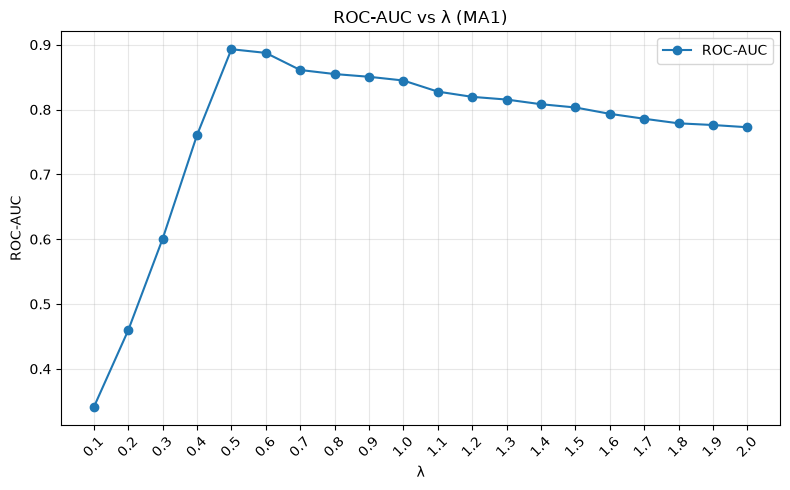

In [8]:
### Cell 8
import matplotlib.pyplot as plt
lambda_list = [0.1, 0.2, 0.3, 0.4, 0.5,
               0.6, 0.7, 0.8, 0.9, 1.0,
               1.1, 1.2, 1.3, 1.4, 1.5,
               1.6, 1.7, 1.8, 1.9, 2.0]
roc_auc_ma1 = [r['ROC-AUC'] for r in all_results['MA1']]

plt.figure(figsize=(8, 5))
plt.plot(lambda_list, roc_auc_ma1, marker='o', linestyle='-',
         color='C0', label='ROC-AUC')
plt.title('ROC-AUC vs λ (MA1)')
plt.xlabel('λ')
plt.ylabel('ROC-AUC')
plt.xticks(lambda_list, rotation=45)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### 🔴 Section 2: New Idea's

#### ⚪ Pre

In [9]:
# ==========================================
# Shared Core Engine & Mathematical Primitives
# ==========================================
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import rankdata, kendalltau, pearsonr, norm
from sklearn.metrics import roc_auc_score, average_precision_score
from scipy.spatial.distance import cdist

# --- Helper Functions from WNCROD_Full_MA.py ---
def _neighbour_interval(x, s, rank, eps):
    k = x.size
    if not eps >= 0:
        z = np.zeros(k, dtype=np.intp)
        return z, z.copy()
    lo = np.zeros(k, dtype=np.intp)
    hi = rank.astype(np.intp, copy=True)
    while True:
        act = lo < hi
        if not act.any(): break
        mid = (lo + hi) >> 1
        ok = np.abs(x - s[mid]) <= eps
        np.copyto(hi, mid, where=act & ok)
        np.copyto(lo, mid + 1, where=act & ~ok)
    left = lo
    lo = rank.astype(np.intp, copy=True)
    hi = np.full(k, k - 1, dtype=np.intp)
    while True:
        act = lo < hi
        if not act.any(): break
        mid = (lo + hi + 1) >> 1
        ok = np.abs(x - s[mid]) <= eps
        np.copyto(lo, mid, where=act & ok)
        np.copyto(hi, mid - 1, where=act & ~ok)
    return left, lo + 1

def _has_outside_neighbour_sorted(x, out_vals, eps):
    res = np.zeros(x.size, dtype=bool)
    if out_vals.size == 0 or not eps >= 0: return res
    s = np.sort(out_vals)
    pos = np.searchsorted(s, x, side="left")
    up = np.minimum(pos, s.size - 1)
    dn = np.maximum(pos - 1, 0)
    np.logical_or((pos < s.size) & (np.abs(x - s[up]) <= eps),
                  (pos > 0) & (np.abs(x - s[dn]) <= eps), out=res)
    return res

def _has_outside_neighbour_dense(x, out_vals, eps, block):
    res = np.zeros(x.size, dtype=bool)
    if out_vals.size == 0: return res
    for start in range(0, x.size, block):
        stop = min(start + block, x.size)
        d = np.abs(x[start:stop, None] - out_vals[None, :])
        np.any(d <= eps, axis=1, out=res[start:stop])
    return res

# --- Extensible Core Engine ---
def _WNCROD_core(data, X_tem, lammda=0.5, delta_override=None, k_overrides=None, return_internals=False, block_size=None, sorted_kernel=True):
    """
    Extensible version of WNCROD_optimized[cite: 11]. 
    Allows injecting custom radii (delta_override) and custom D thresholds (k_overrides).
    """
    data = np.asarray(data)
    n, m = data.shape
    X_idx = np.ascontiguousarray(X_tem, dtype=np.intp).ravel()
    n_X = X_idx.size
    in_X = np.zeros(n, dtype=bool)
    in_X[X_idx] = True
    C_idx = np.flatnonzero(~in_X)

    if delta_override is not None:
        delta = delta_override
    else:
        delta = np.zeros(m)
        ID = np.all(data <= 1, axis=0)
        if ID.any():
            delta[ID] = np.std(data[:, ID], axis=0) / lammda

    if k_overrides is not None:
        k1, k2, k3 = k_overrides
    else:
        D1, D2, D3 = m / 3, m / 2, 0.9 * m
        om = np.arange(m + 1)
        s1, s2, s3 = om <= D1, om >= D2, om >= D3
        k1 = m - int(om[s1].max()) if s1.any() else None
        k2 = m - int(om[s2].min()) if s2.any() else None
        k3 = m - int(om[s3].min()) if s3.any() else None

    work = np.ascontiguousarray(data, dtype=np.float64)
    VX = np.ascontiguousarray(work[X_idx].T)
    VC = np.ascontiguousarray(work[C_idx].T)

    if block_size is None:
        block_size = min(n_X, max(64, (1 << 21) // n_X))
    block_size = int(min(max(1, int(block_size)), n_X))

    POS = np.empty((m, n_X), dtype=bool)
    hit = np.empty((n_X, m), dtype=np.float64)
    
    if sorted_kernel:
        rank_all = np.empty((m, n_X), dtype=np.int32)
        lo_all = np.empty((m, n_X), dtype=np.int32)
        hi_all = np.empty((m, n_X), dtype=np.int32)
        iota = np.arange(n_X, dtype=np.intp)

    for j in range(m):
        v, eps = VX[j], delta[j]
        if sorted_kernel:
            order = np.argsort(v, kind="stable")
            s = v[order]
            rank = np.empty(n_X, dtype=np.intp)
            rank[order] = iota
            lo, hi = _neighbour_interval(v, s, rank, eps)
            rank_all[j] = rank
            lo_all[j] = lo
            hi_all[j] = hi
            hit[:, j] = hi - lo
            POS[j] = ~_has_outside_neighbour_sorted(v, VC[j], eps)
        else:
            POS[j] = ~_has_outside_neighbour_dense(v, VC[j], eps, block_size)

    NIB = ~POS
    NEB = NIB.all(axis=0)
    NPB = NIB & ~NEB

    gemm_dt = np.float32 if n_X < (1 << 24) else np.float64
    NPB_f = np.ascontiguousarray(NPB.T, dtype=gemm_dt)
    POS_f = np.ascontiguousarray(POS.T, dtype=gemm_dt)

    cnt_dt = np.uint8 if m <= 255 else (np.uint16 if m <= 65535 else np.uint32)
    cnt = np.empty((block_size, n_X), dtype=cnt_dt)
    buf1 = np.empty((block_size, n_X), dtype=bool)
    buf2 = np.empty((block_size, n_X), dtype=bool)
    fbuf = np.empty((block_size, n_X), dtype=gemm_dt)
    dbuf = None if sorted_kernel else np.empty((block_size, n_X), np.float64)

    neb_cnt = np.zeros(n_X, dtype=np.float64)
    npb_cnt = np.zeros((n_X, m), dtype=np.float64)
    pos_cnt = np.zeros((n_X, m), dtype=np.float64)

    for start in range(0, n_X, block_size):
        stop = min(start + block_size, n_X)
        b = stop - start
        c, a, t = cnt[:b], buf1[:b], buf2[:b]
        c.fill(0)
        for j in range(m):
            if sorted_kernel:
                r = rank_all[j]
                np.greater_equal(r, lo_all[j][start:stop, None], out=a)
                np.less(r, hi_all[j][start:stop, None], out=t)
                np.logical_and(a, t, out=a)
            else:
                v, d = VX[j], dbuf[:b]
                np.subtract(v[start:stop, None], v[None, :], out=d)
                np.abs(d, out=d)
                np.less_equal(d, delta[j], out=a)
                hit[start:stop, j] = np.count_nonzero(a, axis=1)
            c += a

        if k1 is not None:
            np.greater_equal(c, k1, out=a)
            np.logical_and(a, NEB, out=a)
            neb_cnt[start:stop] = np.count_nonzero(a, axis=1)
        if k2 is not None:
            np.less_equal(c, k2, out=a)
            np.copyto(fbuf[:b], a)
            npb_cnt[start:stop] = fbuf[:b] @ NPB_f
        if k3 is not None:
            np.less_equal(c, k3, out=a)
            np.copyto(fbuf[:b], a)
            pos_cnt[start:stop] = fbuf[:b] @ POS_f

    if return_internals:
        return {
            'neb_cnt': neb_cnt, 'npb_cnt': npb_cnt, 'pos_cnt': pos_cnt,
            'hit': hit, 'NEB': NEB, 'NPB': NPB, 'POS': POS, 'n_X': n_X
        }

    weight = 1 - np.sqrt(hit / n_X)
    ndf = neb_cnt[:, None] + pos_cnt + npb_cnt
    return np.mean((ndf / n_X) * weight, axis=1)

# --- Plotting & Evaluation Wrapper ---
def evaluate_and_plot(variant_name, func, X_data, y_labels, ma_dict):
    lambda_list = np.arange(0.1, 2.1, 0.1)
    results = {name: {'roc': [], 'ap': []} for name in ma_dict}
    
    print(f"\nEvaluating {variant_name} with λ grid search [0.1 -> 2.0]...")
    for lam in lambda_list:
        for name, X_tem in ma_dict.items():
            t0 = time.perf_counter()
            scores = func(X_data, X_tem, lam)
            elapsed = time.perf_counter() - t0
            roc = roc_auc_score(y_labels[X_tem], scores)
            ap = average_precision_score(y_labels[X_tem], scores)
            results[name]['roc'].append(roc)
            results[name]['ap'].append(ap)
            
    plt.figure(figsize=(14, 5))
    plt.suptitle(f"{variant_name} Performance", fontsize=14, y=1.05)

    plt.subplot(1, 2, 1)
    for name in ma_dict:
        plt.plot(lambda_list, results[name]['roc'], marker='o', label=name)
    plt.title('ROC-AUC vs λ')
    plt.xlabel('λ')
    plt.ylabel('ROC-AUC')
    plt.grid(alpha=0.3)
    plt.legend()

    plt.subplot(1, 2, 2)
    for name in ma_dict:
        plt.plot(lambda_list, results[name]['ap'], marker='s', label=name)
    plt.title('Average Precision (AP) vs λ')
    plt.xlabel('λ')
    plt.ylabel('AP')
    plt.grid(alpha=0.3)
    plt.legend()

    plt.tight_layout()
    plt.show()

    print(f"--- Best Results for {variant_name} ---")
    for name in ma_dict:
        best_ap = max(results[name]['ap'])
        best_roc = max(results[name]['roc'])
        print(f"[{name}] Best ROC-AUC: {best_roc:.4f} | Best AP: {best_ap:.4f}")

# Dict mapping to feed the evaluator
ma_dict_subsets = {'MA1': X_tem_ma1, 'MA2': X_tem_ma2, 'MA3': X_tem_ma3}

#### ⚪ Variant 1


Evaluating Variant 1 (L-Moment Radius) with λ grid search [0.1 -> 2.0]...


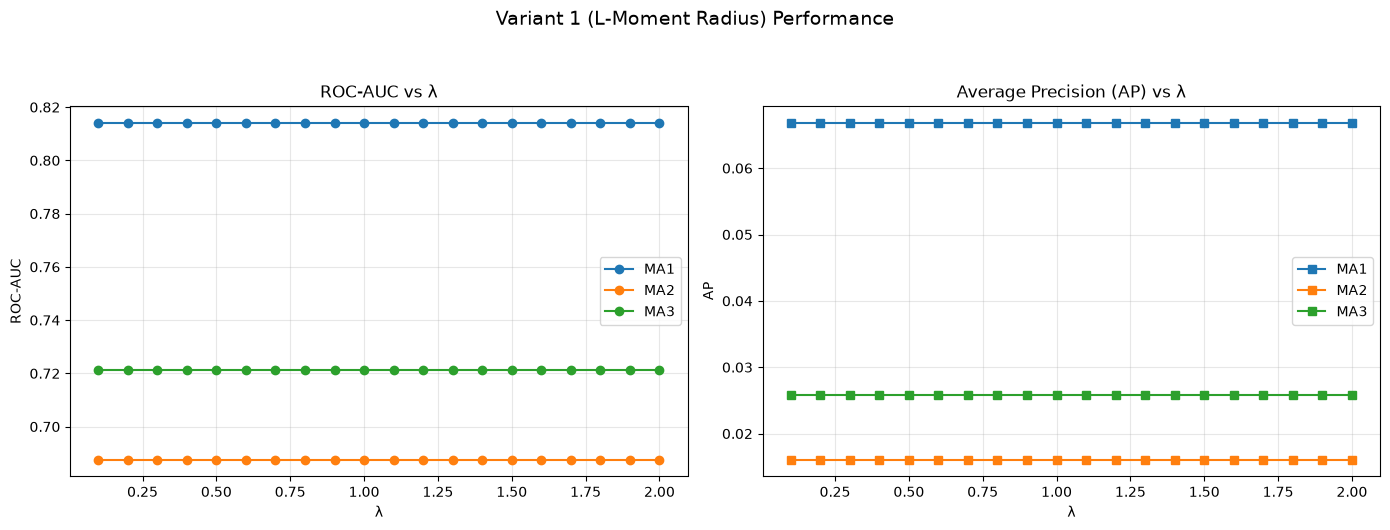

--- Best Results for Variant 1 (L-Moment Radius) ---
[MA1] Best ROC-AUC: 0.8142 | Best AP: 0.0669
[MA2] Best ROC-AUC: 0.6876 | Best AP: 0.0161
[MA3] Best ROC-AUC: 0.7212 | Best AP: 0.0258


In [10]:
# ==========================================
# Variant 1: Directive 2 - L-Moment Kurtosis-Adjusted Radius
# ==========================================

def get_l_moment_radius(data, ID):
    """
    Computes distribution-agnostic radius eps^(3) based on L-moments (Eq. 16).

    """
    n, m = data.shape
    delta = np.zeros(m)
    for j in range(m):
        if ID[j]:
            col = data[:, j]
            valid = col[~np.isnan(col)]
            nn = len(valid)
            kappa = 0.9
            
            # L-Moment Kurtosis (tau_4) Calculation
            if nn >= 4:
                x = np.sort(valid)
                i = np.arange(1, nn + 1)
                b0 = np.mean(x)
                b1 = np.sum((i - 1) * x) / (nn * (nn - 1))
                b2 = np.sum((i - 1) * (i - 2) * x) / (nn * (nn - 1) * (nn - 2))
                b3 = np.sum((i - 1) * (i - 2) * (i - 3) * x) / (nn * (nn - 1) * (nn - 2) * (nn - 3))
                l2 = 2 * b1 - b0
                if l2 != 0:
                    l4 = 20 * b3 - 30 * b2 + 12 * b1 - b0
                    tau4 = l4 / l2
                    d_tau4 = tau4 - 0.1226
                    kappa = 0.9 * (1 + max(d_tau4, -0.9)) ** -0.2

            med = np.median(col)
            mad = np.median(np.abs(col - med))
            madn = 1.4826 * mad
            q75, q25 = np.percentile(col, [75, 25])
            iqr = q75 - q25
            
            candidates = [s for s in (madn, iqr / 1.34) if s > 1e-12]
            if not candidates:
                delta[j] = 0.0
            else:
                scale = min(candidates)
                delta[j] = max(kappa * scale * (n ** -0.2), 1.0 / n)
    return delta

def WNCROD_v1_LMoment(data, X_tem, lammda=None):
    """
    Parameter-free variant. Ignores lammda entirely.
    """
    ID = np.all(data <= 1, axis=0)
    delta_LM = get_l_moment_radius(data, ID)
    return _WNCROD_core(data, X_tem, delta_override=delta_LM)

evaluate_and_plot("Variant 1 (L-Moment Radius)", WNCROD_v1_LMoment, X, y, ma_dict_subsets)

#### ⚪ Variant 2


Evaluating Variant 2 (Dual-Dispersion Weight) with λ grid search [0.1 -> 2.0]...


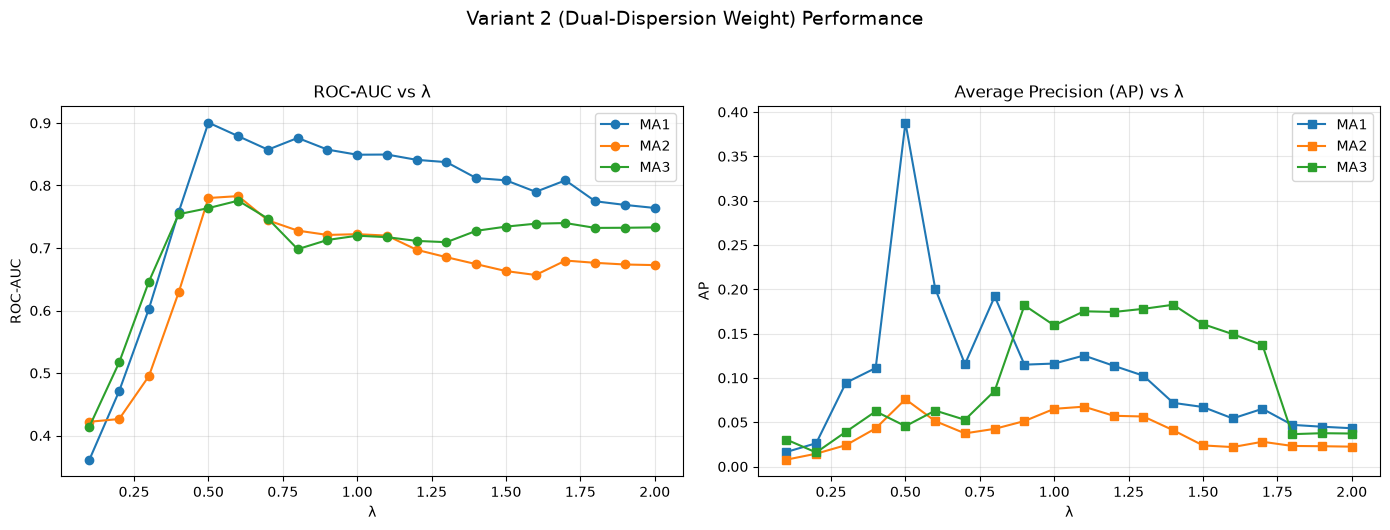

--- Best Results for Variant 2 (Dual-Dispersion Weight) ---
[MA1] Best ROC-AUC: 0.9006 | Best AP: 0.3880
[MA2] Best ROC-AUC: 0.7830 | Best AP: 0.0760
[MA3] Best ROC-AUC: 0.7757 | Best AP: 0.1825


In [11]:
# ==========================================
# Variant 2: Directive 3 - Dual-Dispersion Global Weighting
# ==========================================

def WNCROD_v2_DualDispersion(data, X_tem, lammda=0.5):
    """
    Replaces global weighting with Dual-Dispersion (CV * Gini) rank normalization.
    """
    internals = _WNCROD_core(data, X_tem, lammda=lammda, return_internals=True)
    
    n_X = internals['n_X']
    m = data.shape[1]
    hit = internals['hit']
    
    # Granule occupancy
    rho = hit / n_X
    mean_rho = np.mean(rho, axis=0)
    std_rho = np.std(rho, axis=0)
    CV = std_rho / (mean_rho + 1.0 / data.shape[0])
    
    Gini = np.zeros(m)
    for j in range(m):
        r_sorted = np.sort(rho[:, j])
        sum_r = np.sum(r_sorted)
        if sum_r > 1e-12:
            idx = np.arange(1, n_X + 1)
            Gini[j] = (2 * np.sum(idx * r_sorted)) / (n_X * sum_r) - (n_X + 1) / n_X

    # Dual-Dispersion & Rank Normalization
    S = np.sqrt(CV * Gini)
    W_2 = rankdata(S) / m
    
    weight = 1 - np.sqrt(rho)
    ndf = internals['neb_cnt'][:, None] + internals['pos_cnt'] + internals['npb_cnt']
    
    # Apply new global weight W_2
    return np.mean((ndf / n_X) * weight * W_2[None, :], axis=1)

evaluate_and_plot("Variant 2 (Dual-Dispersion Weight)", WNCROD_v2_DualDispersion, X, y, ma_dict_subsets)

#### ⚪ Variant 3


Evaluating Variant 3 (Copula-Residual Feature Bank) with λ grid search [0.1 -> 2.0]...


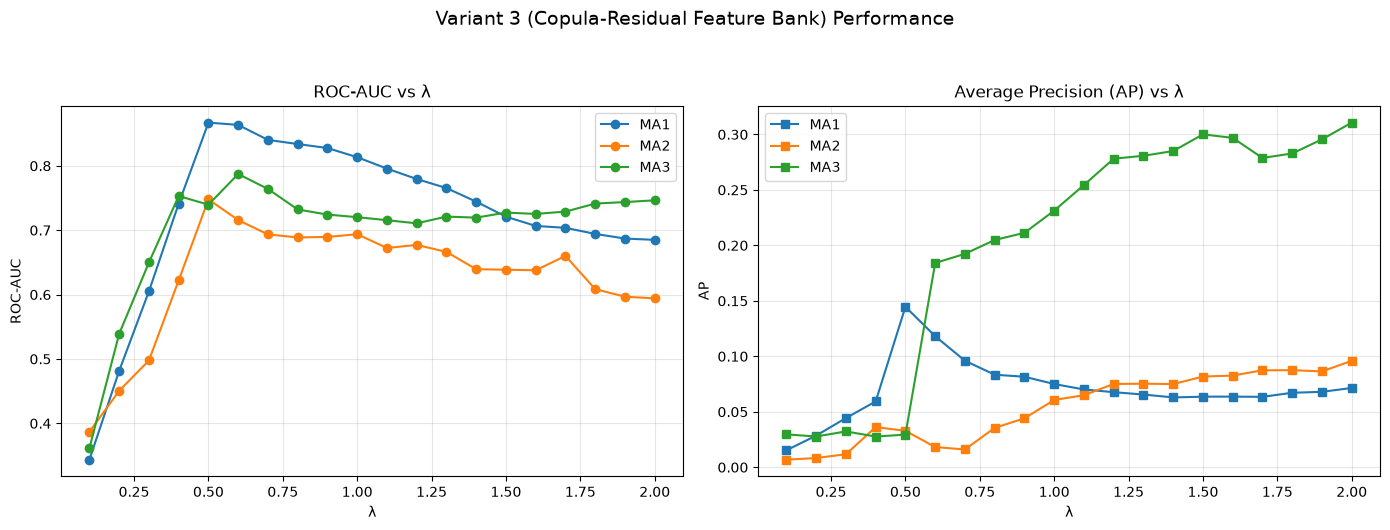

--- Best Results for Variant 3 (Copula-Residual Feature Bank) ---
[MA1] Best ROC-AUC: 0.8671 | Best AP: 0.1446
[MA2] Best ROC-AUC: 0.7479 | Best AP: 0.0960
[MA3] Best ROC-AUC: 0.7873 | Best AP: 0.3106


In [12]:
# ==========================================
# Variant 3: Directive 1 - MI-Guided Copula-Residual Bank
# ==========================================

def get_copula_features(data, ID, alpha=0.5):
    """
    Generates Top-K Gaussian Copula Residual features + 1 Linear SPE feature (Eq 15a-15b)[cite: 10].
    """
    num_cols = np.where(ID)[0]
    m_num = len(num_cols)
    if m_num < 2: return None
    n = data.shape[0]

    # Linear SPE
    Z = np.zeros((n, m_num))
    for idx, c in enumerate(num_cols):
        col = data[:, c]
        med = np.median(col)
        mad = 1.4826 * np.median(np.abs(col - med))
        sigma = mad if mad > 1e-12 else (np.std(col) if np.std(col) > 1e-12 else 1.0)
        Z[:, idx] = (col - med) / sigma

    r = max(1, min(int(np.ceil(np.log2(m_num + 1))), m_num - 1))
    Z_k = Z.copy()
    V = []
    for _ in range(r):
        u = np.ones(m_num) / np.sqrt(m_num)
        for _ in range(10):
            u_next = Z_k.T @ (Z_k @ u)
            nrm = np.linalg.norm(u_next)
            if nrm < 1e-12: break
            u = u_next / nrm
        V.append(u)
        Z_k = Z_k - np.outer(Z_k @ u, u)

    Z_sq = np.sum(Z**2, axis=1)
    proj_sq = sum((Z @ u)**2 for u in V)
    J = np.maximum(Z_sq - proj_sq, 0)
    c_spe = (J - J.min()) / (J.max() - J.min()) if J.max() > J.min() else np.zeros(n)

    # Copula Pairs[cite: 10]
    K_target = min(int(np.ceil(alpha * data.shape[1])) - 1, m_num * (m_num - 1) // 2)
    if K_target <= 0: return c_spe[:, None]

    deltas, pairs = [], []
    for j in range(m_num):
        for k in range(j+1, m_num):
            cj, ck = data[:, num_cols[j]], data[:, num_cols[k]]
            tau, _ = kendalltau(cj, ck)
            if np.isnan(tau): tau = 0
            pr, _ = pearsonr(cj, ck)
            if np.isnan(pr): pr = 0

            rho_hat = np.sin(np.pi / 2 * tau)
            mi_hat = -0.5 * np.log(max(1e-12, 1 - rho_hat**2))
            mi_lin = -0.5 * np.log(max(1e-12, 1 - pr**2))
            deltas.append(mi_hat - mi_lin)
            pairs.append((num_cols[j], num_cols[k], rho_hat))

    top_idx = np.argsort(deltas)[-K_target:]
    c_new_list = []
    for idx in top_idx:
        cj_idx, ck_idx, rho_hat = pairs[idx]
        cj, ck = data[:, cj_idx], data[:, ck_idx]
        
        Uj = (rankdata(cj) - 0.5) / n
        Uk = (rankdata(ck) - 0.5) / n
        rho_tilde = np.sign(rho_hat) * min(abs(rho_hat), 1 - 1/n)
        u, v = norm.ppf(Uj), norm.ppf(Uk)

        c_val = (rho_tilde**2 * (u**2 + v**2) - 2*rho_tilde*u*v) / (2*(1 - rho_tilde**2)) + 0.5 * np.log(1 - rho_tilde**2)
        c_val = np.clip(c_val, 0, None)
        if c_val.max() > c_val.min():
            c_new_list.append((c_val - c_val.min()) / (c_val.max() - c_val.min()))

    if c_new_list:
        return np.column_stack([c_spe] + c_new_list)
    return c_spe[:, None]

def WNCROD_v3_CopulaBank(data, X_tem, lammda=0.5):
    ID = np.all(data <= 1, axis=0)
    c_aug = get_copula_features(data, ID)
    if c_aug is not None:
        data = np.column_stack((data, c_aug))
    return _WNCROD_core(data, X_tem, lammda=lammda)

evaluate_and_plot("Variant 3 (Copula-Residual Feature Bank)", WNCROD_v3_CopulaBank, X, y, ma_dict_subsets)

#### ⚪ Variant 4


Evaluating Variant 4 (Stabilized Tiered NDF) with λ grid search [0.1 -> 2.0]...


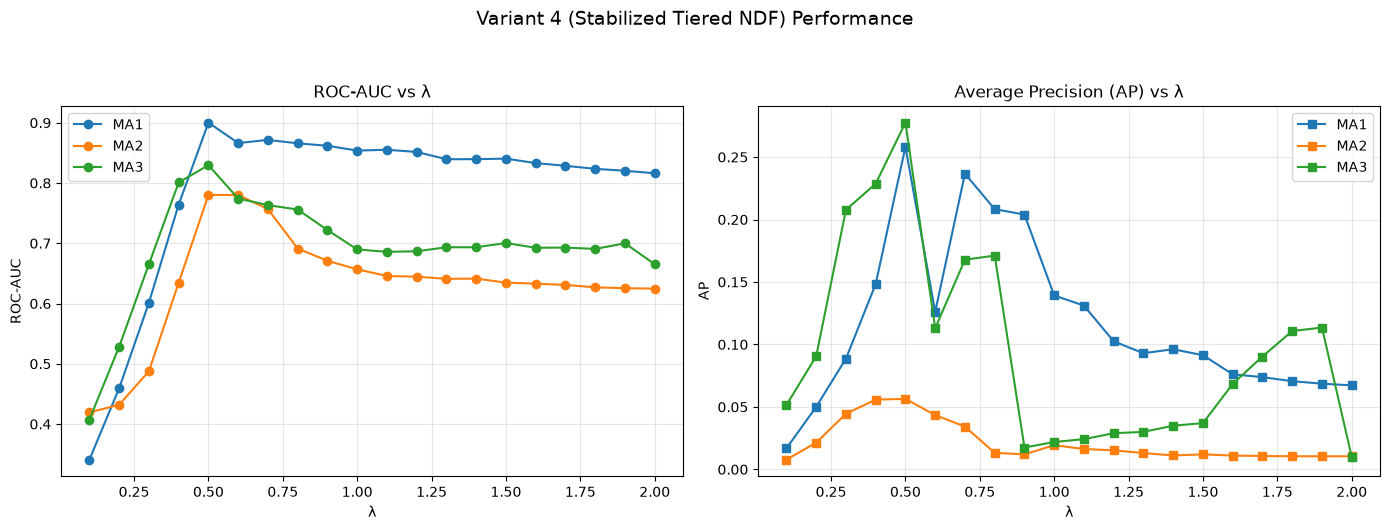

--- Best Results for Variant 4 (Stabilized Tiered NDF) ---
[MA1] Best ROC-AUC: 0.9002 | Best AP: 0.2582
[MA2] Best ROC-AUC: 0.7802 | Best AP: 0.0564
[MA3] Best ROC-AUC: 0.8297 | Best AP: 0.2776


In [16]:
# ==========================================
# Variant 4: Directive 4 - Stabilizing Tiered Evidence[cite: 10]
# ==========================================

def log_rarity(R_size, X_size):
    """Log-smoothed (IDF-style) rarity weight (Eq. 18a)[cite: 10]"""
    if X_size == 0: return 1.0
    return -np.log2((R_size + 0.5) / (X_size + 1)) / -np.log2(0.5 / (X_size + 1))

def WNCROD_v4_StabilizedTiered(data, X_tem, lammda=0.5):
    m = data.shape[1]
    
    # Base Radius
    delta = np.zeros(m)
    ID = np.all(data <= 1, axis=0)
    if ID.any():
        delta[ID] = np.std(data[:, ID], axis=0) / lammda
        
    # Empirical Quantiles for D thresholds (Eq. 18b)[cite: 10]
    sub_X = np.random.choice(X_tem, min(len(X_tem), 1500), replace=False)
    nom_sub = np.zeros((len(sub_X), len(sub_X)))
    
    for j in range(m):
        col_data = data[sub_X, j].reshape(-1, 1)
        nom_sub += (cdist(col_data, col_data, 'cityblock') > delta[j]).astype(int)

    D1 = np.percentile(nom_sub, 33.33)
    D2 = np.percentile(nom_sub, 50.0)
    D3 = np.percentile(nom_sub, 90.0)

    # Convert to corresponding internal counters
    k1 = max(0, min(m, int(np.ceil(m - D1))))
    k2 = max(0, min(m, int(np.floor(m - D2))))
    k3 = max(0, min(m, int(np.floor(m - D3))))
    
    internals = _WNCROD_core(data, X_tem, delta_override=delta, k_overrides=(k1, k2, k3), return_internals=True)
    n_X = internals['n_X']
    
    w_NEB = log_rarity(np.sum(internals['NEB']), n_X)
    w_NPB = np.zeros(m)
    w_POS = np.zeros(m)
    
    # FIX: internals['NPB'] and 'POS' shapes are (m, n_X). Indexing corrected to [j, :]
    for j in range(m):
        w_NPB[j] = log_rarity(np.sum(internals['NPB'][j, :]), n_X) 
        w_POS[j] = log_rarity(np.sum(internals['POS'][j, :]), n_X)

    # FIX: axis=1 ensures summing across objects, returning a vector of shape (m,)
    denom = w_NEB * np.sum(internals['NEB']) + w_NPB * np.sum(internals['NPB'], axis=1) + w_POS * np.sum(internals['POS'], axis=1)
    denom[denom == 0] = 1.0 # Safe guard
    
    ndf_tiered = (w_NEB * internals['neb_cnt'][:, None] + 
                  w_NPB[None, :] * internals['npb_cnt'] + 
                  w_POS[None, :] * internals['pos_cnt']) / denom[None, :]
                  
    weight = 1 - np.sqrt(internals['hit'] / n_X)
    return np.mean(ndf_tiered * weight, axis=1)

evaluate_and_plot("Variant 4 (Stabilized Tiered NDF)", WNCROD_v4_StabilizedTiered, X, y, ma_dict_subsets)

#### ⚪ Variant 5


Evaluating Variant 5 (Asymmetric Reverse-Neighbor) with λ grid search [0.1 -> 2.0]...


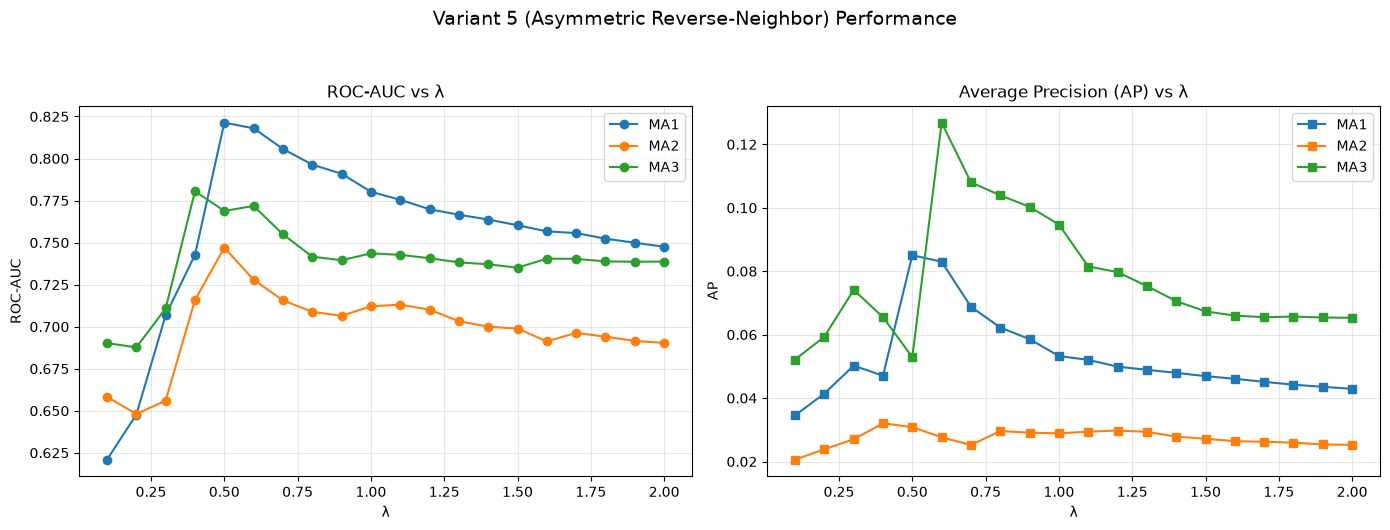

--- Best Results for Variant 5 (Asymmetric Reverse-Neighbor) ---
[MA1] Best ROC-AUC: 0.8214 | Best AP: 0.0850
[MA2] Best ROC-AUC: 0.7470 | Best AP: 0.0320
[MA3] Best ROC-AUC: 0.7805 | Best AP: 0.1268


In [17]:
# ==========================================
# Variant 5: Novel V5 - Asymmetric Reverse-Neighbor Isolation
# ==========================================

def WNCROD_v5_AsymReverse(data, X_tem, lammda=0.5):
    """
    Fuses MNOF with Asymmetric Isolation Factor (AIF) computed via reverse neighbors (Eq. 19)[cite: 10].
    """
    n, m = data.shape
    n_X = len(X_tem)
    k_nn = max(1, int(np.ceil(n ** 0.4)))
    AIF = np.zeros((n_X, m))
    for j in range(m):
        dists = cdist(data[:, [j]], data[:, [j]], 'cityblock')
        eps_y = np.sort(dists, axis=1)[:, min(k_nn, n-1)]
        
        for i, x_idx in enumerate(X_tem):
            rn = np.sum(dists[x_idx, :] <= eps_y) - 1 # excluding self
            AIF[i, j] = max(0, 1 - rn / k_nn)      
    aif_score = np.mean(AIF, axis=1)
    if aif_score.max() > aif_score.min():
        aif_score = (aif_score - aif_score.min()) / (aif_score.max() - aif_score.min())
    else:
        aif_score = np.zeros(n_X)
    base_mnof = _WNCROD_core(data, X_tem, lammda=lammda)
    return 0.5 * (base_mnof + aif_score)

evaluate_and_plot("Variant 5 (Asymmetric Reverse-Neighbor)", WNCROD_v5_AsymReverse, X, y, ma_dict_subsets)

#### ⚪ Variant 6


Evaluating Variant 6 (Multigranulation Consensus) with λ grid search [0.1 -> 2.0]...


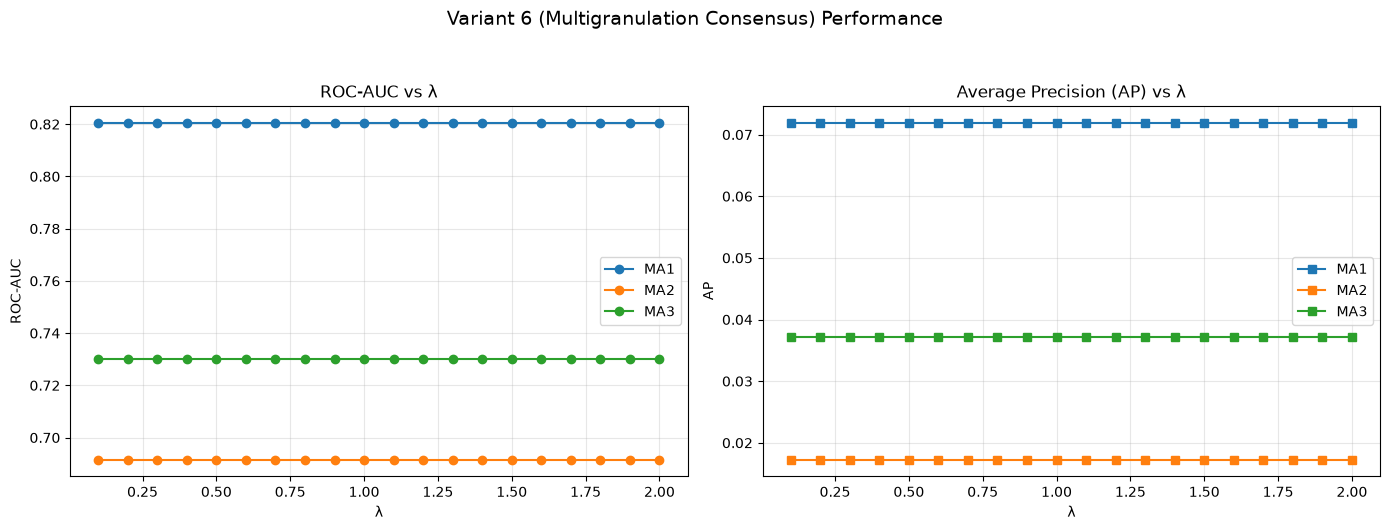

--- Best Results for Variant 6 (Multigranulation Consensus) ---
[MA1] Best ROC-AUC: 0.8206 | Best AP: 0.0719
[MA2] Best ROC-AUC: 0.6916 | Best AP: 0.0173
[MA3] Best ROC-AUC: 0.7300 | Best AP: 0.0372


In [18]:
# ==========================================
# Variant 6: Novel V6 - Multigranulation Consensus Ensemble
# ==========================================

def WNCROD_v6_Multigranulation(data, X_tem, lammda=None):
    """
    Optimistic MGRS fusion over T=3 dyadic octave scales around L-moment radius (Eq. 20)[cite: 10].
    Parameter-free.
    """
    ID = np.all(data <= 1, axis=0)
    delta_base = get_l_moment_radius(data, ID) # from Cell 10
    
    ndf_scales = []
    hit_base = None
    
    for scale in [0.5, 1.0, 2.0]:
        delta_t = scale * delta_base
        internals = _WNCROD_core(data, X_tem, delta_override=delta_t, return_internals=True)
        ndf = internals['neb_cnt'][:, None] + internals['pos_cnt'] + internals['npb_cnt']
        ndf_scales.append(ndf)
        if scale == 1.0:
            hit_base = internals['hit']
            n_X = internals['n_X']
            
    # Optimistic Fusion (Max over scales)
    ndf_opt = np.maximum.reduce(ndf_scales)
    
    # Weight using base granularity
    weight = 1 - np.sqrt(hit_base / n_X)
    return np.mean((ndf_opt / n_X) * weight, axis=1)

evaluate_and_plot("Variant 6 (Multigranulation Consensus)", WNCROD_v6_Multigranulation, X, y, ma_dict_subsets)

#### ⚪ 5. 